In [1]:
import numpy as np
import pickle
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt

sns.set_theme(style='darkgrid')

with open('../data/irnet_reflectance_parameters.pickle', 'rb') as f:
    irn = pickle.load(f)

irn.keys()

dict_keys(['all_median_error', 'all_correlationss', 'gt_pixels', 'all_model_outputs'])

In [2]:
irn['all_model_outputs'].shape

(10, 1000)

Text(0.05, 0.85, 'Median error: 0.08\nr: 0.81')

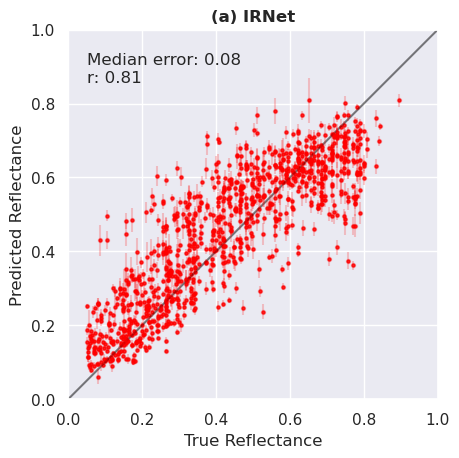

In [3]:
xs = irn['gt_pixels']
ys = irn['all_model_outputs']

xs_arr = np.array(xs)  # True Reflectance
ys_arr = np.array(ys)  # Predicted Reflectance from 10 runs

mean_ys = np.mean(ys_arr, axis=0)  # Compute mean prediction
sem_ys = np.std(ys_arr, axis=0) / np.sqrt(ys_arr.shape[0])  # Compute SEM

# Define x values for the identity line
x_vals = np.linspace(0, 1, 100)

# Plot identity line (ideal predictions)
plt.plot(x_vals, x_vals, color='black', alpha=0.5)

# Scatter mean predictions, with point size proportional to SEM
plt.scatter(xs_arr, mean_ys, color='red', s=4, alpha=0.8)
plt.errorbar(xs_arr, mean_ys, yerr=sem_ys, fmt='o', color='red', markersize=3, alpha=0.2)

# Labels and limits
plt.xlabel('True Reflectance')
plt.ylabel('Predicted Reflectance')
plt.title('(a) IRNet', weight='bold')
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.gca().set_aspect('equal')

# Add text annotation with median error and correlation
plt.text(0.05, 0.85, f"Median error: {np.mean(irn['all_median_error']):.2f}\nr: {np.mean(irn['all_correlationss']):.2f}",
               transform=plt.gca().transAxes, fontsize=12, 
               verticalalignment='bottom', horizontalalignment='left')
